# Global Health Indicators (original notebook, with my comments)
I ran every cell of the provided notebook and added a short comment to each part explaining what it does.

**Dataset:** 10 countries, with columns `Country`, `Life Expectancy` (years), `Health Spending Per Capita` (US$ per person), and `Infant Mortality` (deaths per 1,000 live births).

In [ ]:
# Import the libraries:
# pandas -> tables (DataFrames), matplotlib.pyplot -> basic plotting, seaborn -> nicer statistical plots built on matplotlib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# 1. Load dataset
# read_csv can read straight from a URL; the result is a DataFrame (a table)
df = pd.read_csv("https://raw.githubusercontent.com/duochen/data-science-bootcamp/refs/heads/main/Data/health_data.csv")
# head() shows the first 5 rows so we can check the data loaded correctly
print(df.head())

         Country  Life Expectancy  Health Spending Per Capita  Infant Mortality
0          Japan             84.5                        4500               2.0
1  United States             78.9                       10500               5.7
2          India             69.7                         300              25.0
3        Nigeria             61.2                         150              60.8
4         Norway             82.4                        6500               2.5


In [ ]:
# 2. Summary statistics
# describe() gives count, mean, std, min, quartiles (25%, 50% = median, 75%) and max for every numeric column
print("Summary:")
print(df.describe())

Summary:
       Life Expectancy  Health Spending Per Capita  Infant Mortality
count        10.000000                   10.000000         10.000000
mean         74.680000                 3040.000000         17.020000
std           7.782716                 3550.414686         18.319255
min          61.200000                  150.000000          2.000000
25%          70.350000                  350.000000          3.900000
50%          76.300000                 1100.000000          9.600000
75%          80.550000                 5250.000000         24.800000
max          84.500000                10500.000000         60.800000


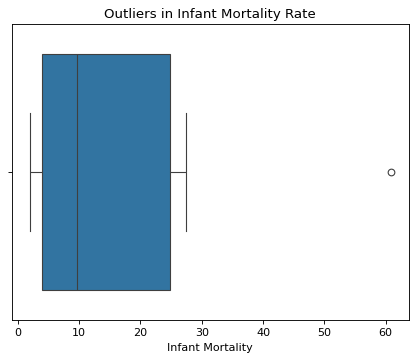

In [ ]:
# 3. Boxplot: Outliers in Infant Mortality
# The box = middle 50% of countries (IQR), the line = median,
# points beyond the whiskers (more than 1.5*IQR past the box) are outliers
sns.boxplot(x=df["Infant Mortality"])
plt.title("Outliers in Infant Mortality Rate")
plt.show()

**My comment on Plot 1:** The original notes say Nigeria *and* South Africa "likely" appear as outliers. When I ran it, only **one** dot appears past the right whisker: Nigeria (60.8). South Africa (27.5) is inside the whisker, so it is high but not an outlier by the 1.5×IQR rule.

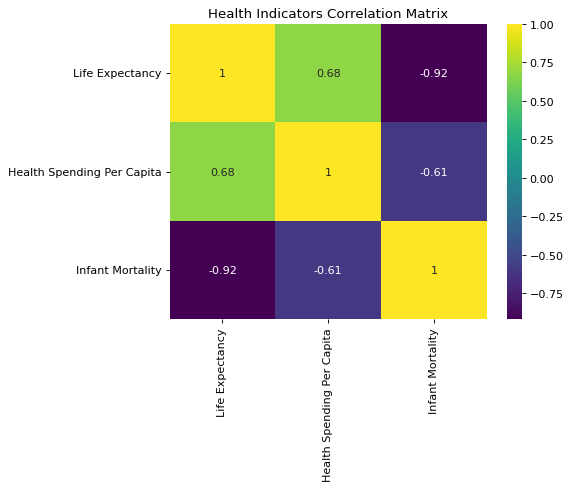

In [ ]:
# 4. Correlation Heatmap
# df.corr() computes the Pearson correlation (-1 to +1) between each pair of numeric columns
# numeric_only=True skips the text column "Country"; annot=True writes the numbers in each square
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="viridis")
plt.title("Health Indicators Correlation Matrix")
plt.show()

**My comment on Plot 2:** Life expectancy and infant mortality are strongly negative (about −0.92). Spending and life expectancy are positive (about +0.68) but weaker than the notes suggest, which makes sense because the US spends the most but does not live the longest.

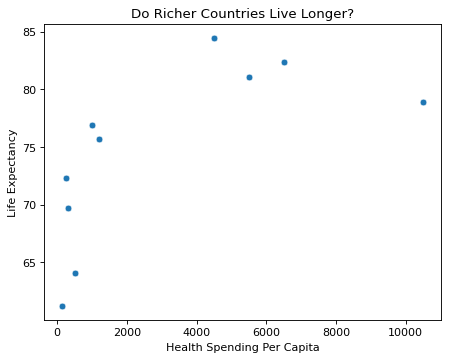

In [ ]:
# 5. Scatter plot: Health Spending vs Life Expectancy
# each dot is one country: x = spending per person, y = life expectancy
sns.scatterplot(x="Health Spending Per Capita", y="Life Expectancy", data=df)
plt.title("Do Richer Countries Live Longer?")
plt.show()

**My comment on Plot 3:** The trend goes up, but it is curved: life expectancy rises fast from $150 to about $1,500, then flattens. The point far to the right is the United States ($10,500 but only 78.9 years). The dots don't have country names, so you have to guess which is which.

## Summary (original)
| Plot | Purpose | Key insight |
|---|---|---|
| Boxplot (Infant Mortality) | Detect outliers | Some countries have extremely high infant mortality |
| Correlation Heatmap | Examine variable relationships | Spending ↑ → Life ↑; Mortality ↑ → Life ↓ |
| Scatter Plot (Spending vs Life) | Visualize health inequality | Wealthier countries generally live longer |